<p><font size="6"><b> Raster operations and raster-vector tools</b></font></p>


> *DS Python for GIS and Geoscience*  
> *November, 2026*
>
> *© 2026, Joris Van den Bossche and Stijn Van Hoey. Licensed under [CC BY 4.0 Creative Commons](http://creativecommons.org/licenses/by/4.0/)*

---

In the previous notebooks, we focused either on vector data or raster data. Often you encounter both types of data and want to combine them. In this notebook, we show *some* examples of typical raster/vector interactions.

In [1]:
import pandas as pd
import numpy as np
import geopandas
import rasterio

import xarray as xr

import matplotlib.pyplot as plt

# `rioxarray`: xarray extension based on rasterio

In the previous notebooks, we already used `rasterio` (https://rasterio.readthedocs.io/en/latest/) to read raster files such as GeoTIFFs (through the `xarray.open_dataarray(...,engine="rasterio")` function). Rasterio provides support for reading and writing geospatial raster data as numpy N-D arrays, mainly through bindings to the GDAL library. 

In addition, rasterio provides a Python API to perform some GIS raster operations (clip, mask, warp, merge, transformation,...) and can be used to only load a subset of a large dataset into memory. However, the main complexity in using `rasterio`, is that the spatial information is decoupled from the data itself (i.e. the numpy array). This means that you need to keep track and organize the extent and metadata throughout the operations (e.g. the "transform") and you need to keep track of what each dimension represents (y-first, as arrays are organized along rows first). Notebook [91_package_rasterio](./91_package_rasterio.ipynb) goes into more depth on the rasterio package itself. 

Enter `rioxarray` (https://vylor.github.io/rioxarray/stable/), which extends xarray with geospatial functionalities powered by rasterio.

In [2]:
import rioxarray

In [3]:
data_file = "./data/herstappe/raster/2020-09-17_Sentinel_2_L1C_True_color.tiff"

In [4]:
data_raw = xr.open_dataarray(data_file, engine="rasterio")
data_raw

<xarray.DataArray 'band_data' (band: 3, y: 227, x: 447)> Size: 1MB
[304407 values with dtype=float32]
Coordinates:
  * band         (band) int64 24B 1 2 3
  * y            (y) float64 2kB 6.578e+06 6.577e+06 ... 6.569e+06 6.568e+06
  * x            (x) float64 4kB 5.935e+05 5.935e+05 ... 6.113e+05 6.114e+05
    spatial_ref  int64 8B ...
Attributes:
    TIFFTAG_XRESOLUTION:     1
    TIFFTAG_YRESOLUTION:     1
    TIFFTAG_RESOLUTIONUNIT:  1 (unitless)
    AREA_OR_POINT:           Area

Once `rioxarray` is imported, it provides a `.rio` accessor on the xarray.DataArray object, which gives access to some properties of the raster data:

In [5]:
data_raw.rio.crs

CRS.from_wkt('PROJCS["WGS 84 / Pseudo-Mercator",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Mercator_1SP"],PARAMETER["central_meridian",0],PARAMETER["scale_factor",1],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],EXTENSION["PROJ4","+proj=merc +a=6378137 +b=6378137 +lat_ts=0 +lon_0=0 +x_0=0 +y_0=0 +k=1 +units=m +nadgrids=@null +wktext +no_defs"],AUTHORITY["EPSG","3857"]]')

In [6]:
data_raw.rio.bounds()

(593476.1968631798, 6568444.042372981, 611391.125367518, 6577549.60336745)

In [7]:
data_raw.rio.resolution()

(40.07813983073409, -40.1126034998577)

In [8]:
data_raw.rio.nodata

In [9]:
data_raw.rio.transform()

Affine(40.07813983073409, 0.0, 593476.1968631798,
       0.0, -40.1126034998577, 6577549.60336745)

For the remainder of this section, we work with the integer converted version with 0 as the no-data value:

In [10]:
data = (data_raw * 255).astype(np.uint8).rio.write_nodata(0)

## Reprojecting rasters

`rioxarray` gives access to a set of raster processing functions from rasterio/GDAL. 

One of those is to reproject (transform and resample) rasters, for example to reproject to different coordinate reference system, up/downsample to a different resolution, etc. In all those case, in the transformation of a source raster to a destination raster, pixel values need to be recalculated. There are different "resampling" methods this can be done: taking the nearest pixel value, calculating the average, a (non-)linear interpolation, etc.

The functionality is available through the `reproject()` method. Let's start with reprojecting the Herstappe tiff to a different CRS:

In [11]:
data.rio.crs

CRS.from_wkt('PROJCS["WGS 84 / Pseudo-Mercator",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Mercator_1SP"],PARAMETER["central_meridian",0],PARAMETER["scale_factor",1],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],EXTENSION["PROJ4","+proj=merc +a=6378137 +b=6378137 +lat_ts=0 +lon_0=0 +x_0=0 +y_0=0 +k=1 +units=m +nadgrids=@null +wktext +no_defs"],AUTHORITY["EPSG","3857"]]')

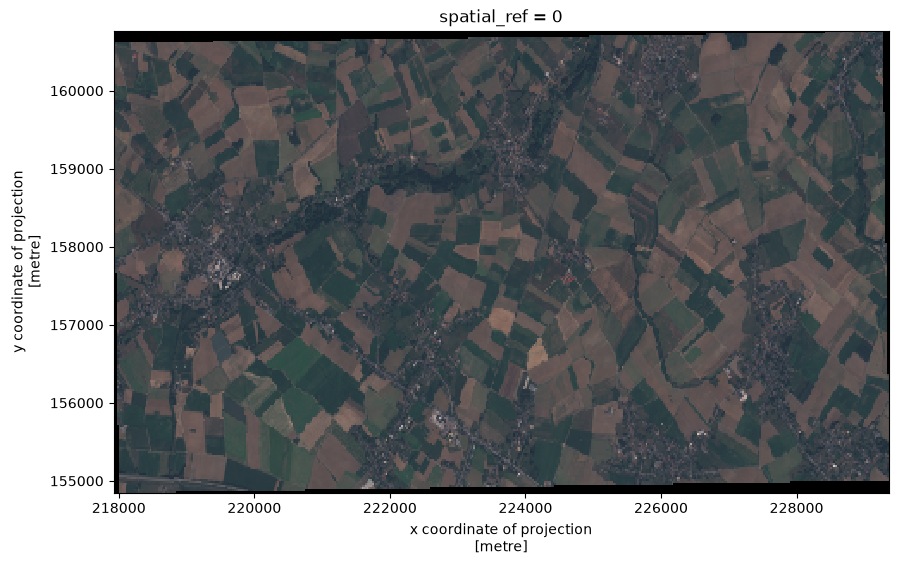

In [12]:
data.rio.reproject("EPSG:31370").plot.imshow(figsize=(10,6))

The default resampling method is "nearest", which is often not a suitable method (especially for continuous data). We can change the method using the `rasterio.enums.Resampling` enumeration (see [docs](https://rasterio.readthedocs.io/en/latest/api/rasterio.enums.html#rasterio.enums.Resampling) for a overview of all methods):

In [13]:
from rasterio.enums import Resampling

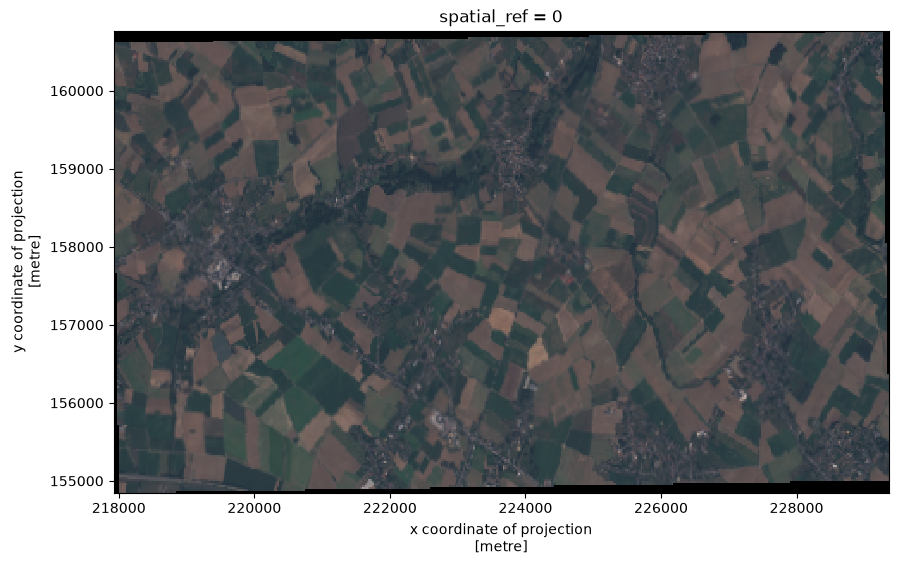

In [14]:
data.rio.reproject("EPSG:31370", resampling=Resampling.bilinear).plot.imshow(figsize=(10,6))

The method can also be used to downsample at the same time:

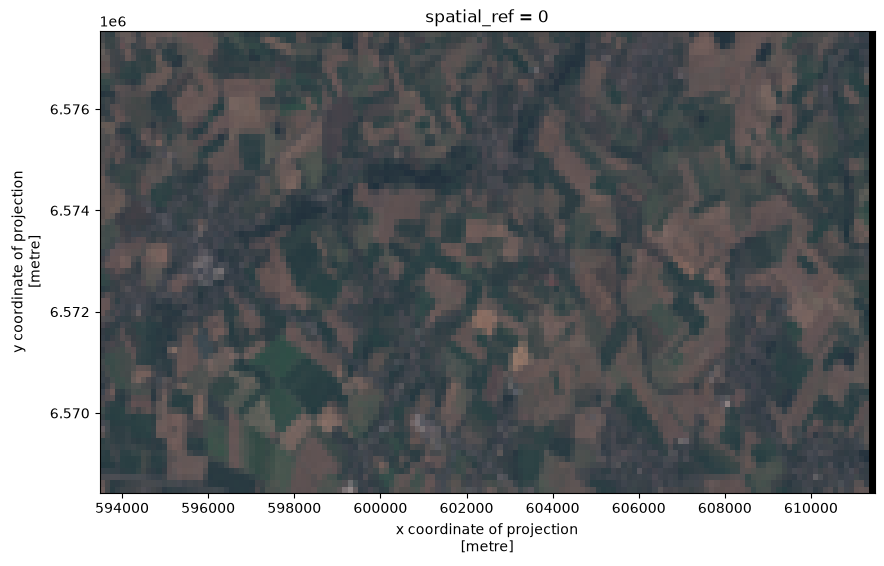

In [15]:
data.rio.reproject(data.rio.crs, resolution=120, resampling=Resampling.cubic).plot.imshow(figsize=(10,6))

## Extract the data you need

In many applications, a specific research area is used. Extracting the data you need from a given raster data set by a vector (polygon) file is a common operation in GIS analysis. We use the clipping example to explain the typical workflow with rioxarray / rasterio.

For our Herstappe example, the study area is available as vector data `./data/herstappe/vector/herstappe.geojson`:

In [16]:
herstappe_vect = geopandas.read_file("./data/herstappe/vector/herstappe.geojson")
herstappe_vect

,gml_id,UIDN,OIDN,TERRID,NISCODE,NAAM,DATPUBLBS,NUMAC,geometry
0,Refgem.202,642.0,37.0,59.0,73028,Herstappe,1831-02-07,,"MULTIPOLYGON (((5.41544 50.72148, 5.41568 50.7..."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

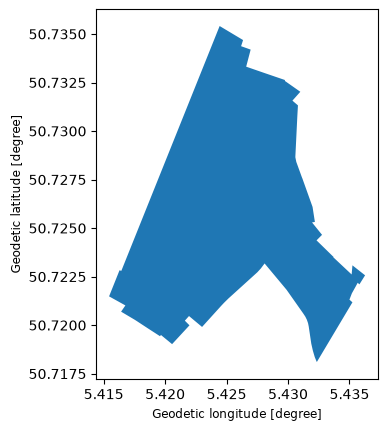

In [17]:
herstappe_vect.plot()

In [18]:
herstappe_vect.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

Make sure both data sets are defined in the same CRS and extracting the geometry can be used as input for the masking:

In [19]:
herstappe_vect = herstappe_vect.to_crs(epsg=3857)

In [20]:
clipped = data.rio.clip(herstappe_vect.geometry)

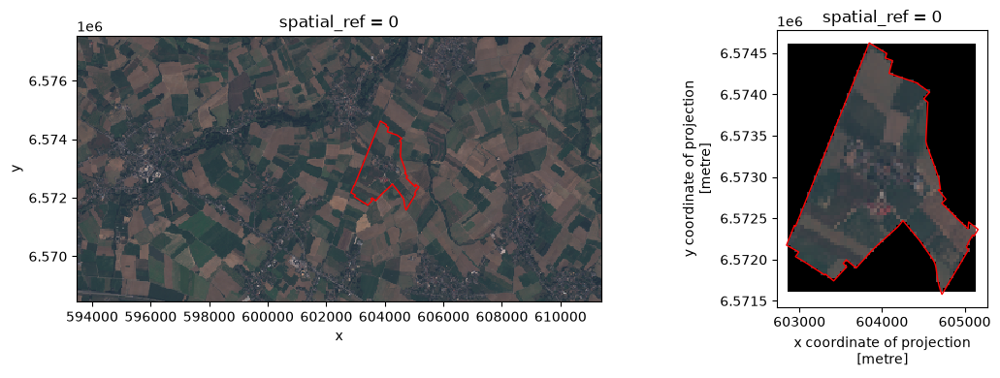

In [21]:
fig, (ax0, ax1) = plt.subplots(ncols=2, figsize=(12,4))
data.plot.imshow(ax=ax0)
herstappe_vect.plot(ax=ax0, facecolor="none", edgecolor="red")

clipped.plot.imshow(ax=ax1)
herstappe_vect.plot(ax=ax1, facecolor="none", edgecolor="red")

fig.tight_layout()

The above uses the `rasterio` package (with the `mask` and `geometry_mask` / `rasterize` functionality) under the hood. This simplifies the operation compared to directly using `rasterio`.


```python
# cfr. The Rasterio workflow

from rasterio.mask import mask

# 1 - Open a data set using the context manager
with rasterio.open(data_file) as src: 

    # 2 - Read and transform the data set by clipping
    out_image, out_transform = mask(src, herstappe_vect.geometry, crop=True)
    
    # 3 - Update the spatial metadata/profile of the data set
    herstappe_profile = src.profile
    herstappe_profile.update({"height": out_image.shape[1],
                              "width": out_image.shape[2],
                              "transform": out_transform})
    # 4 - Save the new data set with the updated metadata/profile                   
    with rasterio.open("./herstappe_masked.tiff", "w", **herstappe_profile) as dest: 
        dest.write(out_image)
```

The [91_package_rasterio](./91_package_rasterio.ipynb) notebook explains this workflow in more detail.

One important difference, though, is that the above `rasterio` workflow will not load the full raster into memory when only loading (clipping) a small part of it. This can also be achieved in `rioxarray` with the `from_disk` keyword.

## Convert vector to raster

### [Intermezzo] - data preparation Zwalm catchment

The following section provides the data preparation and data downloading steps to prepare the 'burning' of the shape of a river into a Digital Elevation Model (DEM) of the river catchment (all locations around the river from which rain ends up in the river). The 'burning' itself is a subtraction of the DEM pixels at locations of the river with a chosen value, i.e. decrease the elevation at locations where a river flows. To do so, we need:

- A Digital Elevation Model (DEM) data set (raster data)
- The shape of the catchment (vector data)
- The river and tributaries (vector data)

To be able to subtract the corresponding river pixels, the river vector data need to be converted into a raster with the same resolution and bounds as the (clipped) DEM.

__Load DEM raster and river vector data__

As example, we are using data from the Zwalm river area in Flanders. 

<div class="alert alert-warning">

**! Manual download needed !** <br>

The digital elevation model (DEM) can be downloaded via the [governmental website](https://download.vlaanderen.be/product/936/configureer): choose number 30 on the map and then click "Downloaden". Finally extract the zip file in `/data` directory. Inside the `data`-directory, the file will be available in the subfolder `DHMVIIDSMRAS5m_k30_LB72/GeoTIFF/DHMVIIDSMRAS5m_k30.tif`.  

</div>

In [22]:
dem_zwalm_file = "data/DHMVIIDSMRAS5m_k30_LB72/GeoTIFF/DHMVIIDSMRAS5m_k30.tif"

In [23]:
dem_zwalm = xr.open_dataarray(dem_zwalm_file, engine="rasterio").sel(band=1).squeeze()
dem_zwalm

<xarray.DataArray 'band_data' (y: 4000, x: 6400)> Size: 102MB
[25600000 values with dtype=float32]
Coordinates:
  * y            (y) float64 32kB 1.78e+05 1.78e+05 ... 1.58e+05 1.58e+05
  * x            (x) float64 51kB 9.8e+04 9.801e+04 ... 1.3e+05 1.3e+05
    band         int64 8B 1
    spatial_ref  int64 8B ...
Attributes:
    VERTICAL_SRS:   EPSG:5110
    AREA_OR_POINT:  Area

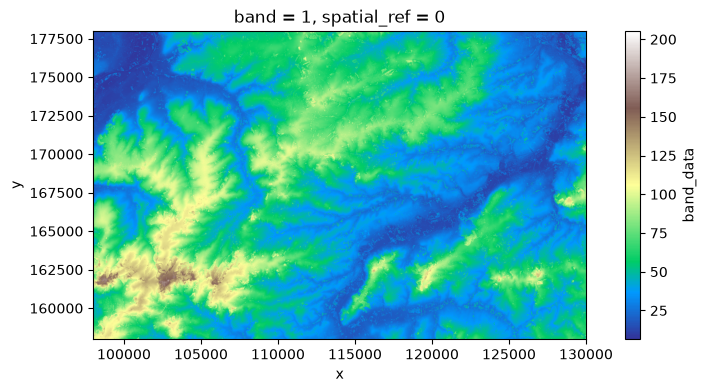

In [24]:
img = dem_zwalm.plot.imshow(
    cmap="terrain", figsize=(10, 4), interpolation='antialiased')
img.axes.set_aspect("equal")

Next, we download the shapes of the rivers in the area through a WFS (Web Feature Service):

In [25]:
import json
import requests

wfs_rivers = "https://geo.api.vlaanderen.be/VHAWaterlopen/wfs"
params = dict(service='WFS', version='1.1.0', request='GetFeature', 
              typeName='VHAWaterlopen:Wlas', outputFormat='json', 
              cql_filter="(VHAZONENR=460)OR(VHAZONENR=461)", srs="31370")

# Fetch data from WFS using requests
r = requests.get(wfs_rivers, params=params)

__Note__: A WFS is a standardized way to share vector GIS data sets on the internet, typically also used by web application, see ['A bit more about WFS'](#A-bit-more-about-WFS) section for more info.

And convert the output of the wfs call to a GeoDataFrame:

In [26]:
# Create GeoDataFrame from geojson - this is vector data
segments = geopandas.GeoDataFrame.from_features(json.loads(r.content), crs="epsg:31370")

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

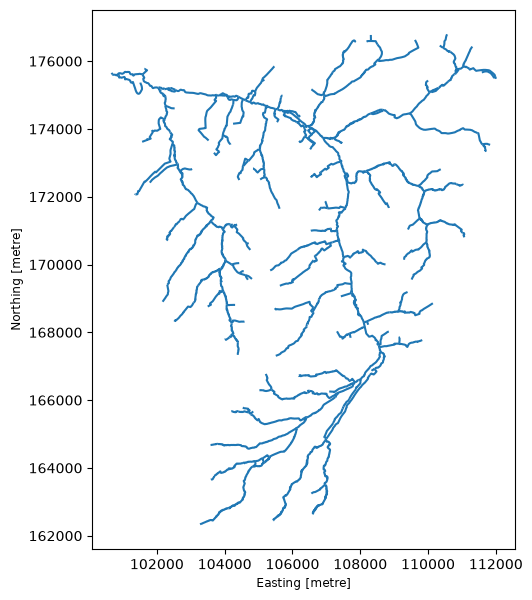

In [27]:
segments.plot(figsize=(8, 7))

__Clip raster with vector__

The catchment extent is much smaller than the DEM file, so clipping the data first will make the computation less heavy and focuses exclusively on the region from which rainfall is collected.

Let's first download the catchment area of the Zwalm river from the Flemish government (using WFS again):

In [28]:
import json
import requests

wfs_bekkens = "https://geo.api.vlaanderen.be/Watersystemen/wfs"
params = dict(service='WFS', version='1.1.0', request='GetFeature',
              typeName='Watersystemen:WsDeelbek', outputFormat='json',
              cql_filter="DEELBEKNM='Zwalm'", srs="31370")

# Fetch data from WFS using requests
r = requests.get(wfs_bekkens, params=params)
catchment = geopandas.GeoDataFrame.from_features(json.loads(r.content), crs="epsg:31370")

Save to a file for later reuse:

In [29]:
# save to file
catchment = catchment.to_crs('epsg:4326') # geojson is default 4326
catchment.to_file("./data/zwalmbekken.geojson", driver="GeoJSON")

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

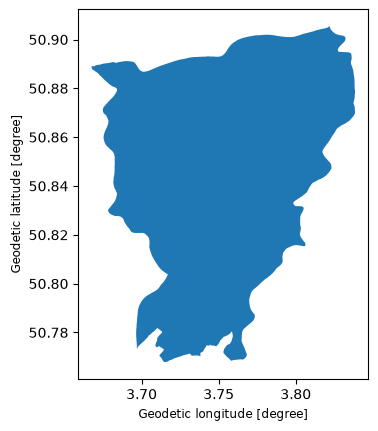

In [30]:
geopandas.read_file("./data/zwalmbekken.geojson").plot()

_1. Clip using rioxarray (rasterio)_

As shown above, we can use rioxarray to clip the raster file:

In [31]:
dem_zwalm = xr.open_dataarray(dem_zwalm_file, engine="rasterio").sel(band=1)
dem_zwalm.spatial_ref

<xarray.DataArray 'spatial_ref' ()> Size: 8B
[1 values with dtype=int64]
Coordinates:
    band         int64 8B 1
    spatial_ref  int64 8B ...
Attributes: (12/18)
    crs_wkt:                        PROJCS["BD72 / Belgian Lambert 72",GEOGCS...
    semi_major_axis:                6378388.0
    semi_minor_axis:                6356911.9461279465
    inverse_flattening:             297.0
    reference_ellipsoid_name:       International 1924
    longitude_of_prime_meridian:    0.0
    ...                             ...
    latitude_of_projection_origin:  90.0
    longitude_of_central_meridian:  4.36748666666667
    false_easting:                  150000.013
    false_northing:                 5400088.438
    spatial_ref:                    PROJCS["BD72 / Belgian Lambert 72",GEOGCS...
    GeoTransform:                   98000.0 5.0 0.0 178000.0 0.0 -5.0

In [32]:
clipped = dem_zwalm.rio.clip(catchment.to_crs('epsg:31370').geometry)
clipped = clipped.squeeze().drop_vars(['band', 'spatial_ref']) # remove redundant coordinates

Using rioxarray's `to_raster()` method, we can also save the result to a new GeoTIFF file:

In [33]:
clipped.rio.to_raster("./dem_masked_rio.tiff")

This DEM raster file used -9999 as the NODATA value, which are read as NaN values:

In [34]:
dem_zwalm.rio.nodata, clipped.rio.nodata

(np.float32(nan), np.float32(nan))

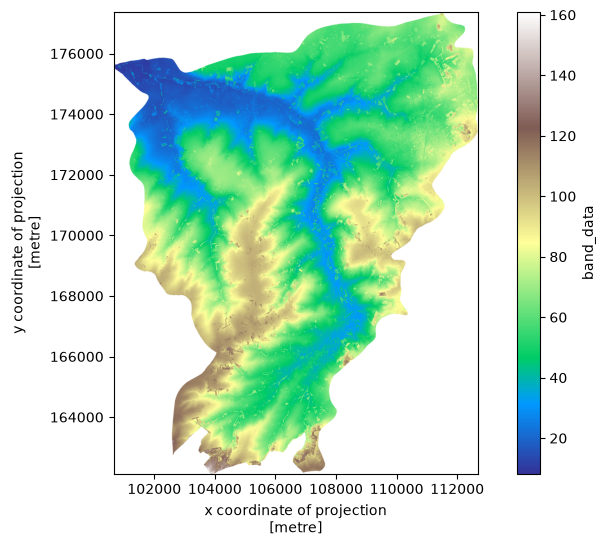

In [35]:
img = clipped.plot.imshow(
    cmap='terrain', figsize=(10, 6), interpolation='antialiased')
img.axes.set_aspect("equal")

_2. (optional) Using GDAL CLI_

If we have the raster and vector files on disk, the [`gdal CLI`](https://gdal.org/programs/index.html) will be very fast to work with (note that GDAL automatically handles the CRS difference of the raster and vector).

In [36]:
! gdal raster clip --like ./data/zwalmbekken.geojson data/DHMVIIDSMRAS5m_k30_LB72/GeoTIFF/DHMVIIDSMRAS5m_k30.tif ./dem_masked_gdal.tiff

ERROR 1: clip: Dataset './dem_masked_gdal.tiff' already exists. You may specify the --overwrite/--append option.
Usage: gdal raster clip [OPTIONS] <INPUT> <OUTPUT>
Try 'gdal raster clip --help' for help.


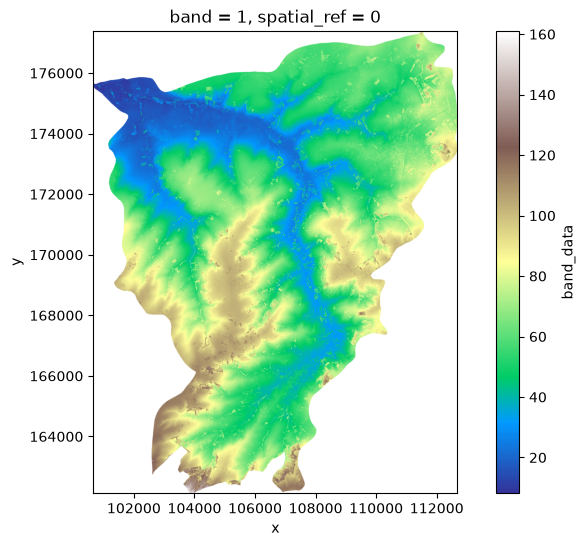

In [37]:
clipped_gdal = xr.open_dataarray("./dem_masked_gdal.tiff", mask_and_scale=True).sel(band=1)
img = clipped_gdal.plot.imshow(
    cmap="terrain", figsize=(10, 6), interpolation='antialiased')
img.axes.set_aspect("equal")

<div class="alert alert-info" style="font-size:120%">

**TIP**: <br>
    
In the GIS world, also other libraries do provide a large set of functionalities as command line instructions with a `FILE IN` -> `RUN COMMAND` -> `FILE OUT` approach, with some of them providing a Python interface as well. Some important once are:
    
- The [`gdal` library](https://gdal.org/programs/index.html#raster-programs) is the open source Swiss Army knife for raster and vector geospatial data handling. 
- The [SAGA GIS](http://www.saga-gis.org/en/index.html) has a [huge set](http://www.saga-gis.org/saga_tool_doc/8.0.0/a2z.html) of CLI commands, going from flow accumulation to classification algorithms.
- The [WhiteboxTools](https://www.whiteboxgeo.com/geospatial-software/) is another example of a library with a lot of functionalities, e.g. hydrological, agricultural and terrain analysis tools.
    
Other important initiatives like [Grass](https://grasswiki.osgeo.org/wiki/GRASS-Wiki) and [PCRaster](https://pcraster.geo.uu.nl/) are worthwhile to check out. Most of these libraries of tools can also be used with QGIS.
    
__NOTE:__ You can run a CLI command inside a Jupyter Notebook by prefixing it with the `!` character.

</div>

### Convert vector to raster

To create a raster with the vector converted into pixels, we can use the `rasterio.features.rasterize` function. This expects a list of (shape, value) tuples, and an output image shape and transform. Here, we will create a new raster image with the same shape and extent as the DEM above. And we first take a buffer of the river lines:

In [38]:
clipped.rio.to_raster("zwalm_clip_test.tif")

In [39]:
import rasterio.features

In [40]:
segments_buffered = segments.geometry.buffer(100)
river_raster = rasterio.features.rasterize(
    segments_buffered, 
    out_shape=clipped.shape, 
    transform=clipped.rio.transform())

In [41]:
type(river_raster)

numpy.ndarray

The output of the rasterio function is a Numpy array. Let's convert to xarray objects

In [42]:
ds_zwalm = clipped.to_dataset(name="dem").squeeze()
ds_zwalm["river"] = xr.DataArray(data=river_raster, coords=clipped.coords)
ds_zwalm["dem_burned"] = ds_zwalm["dem"] - ds_zwalm["river"]*20

As the river is now converted in a raster with the same pixels and boundaries as our DEM, we can burn the river into the DEM:

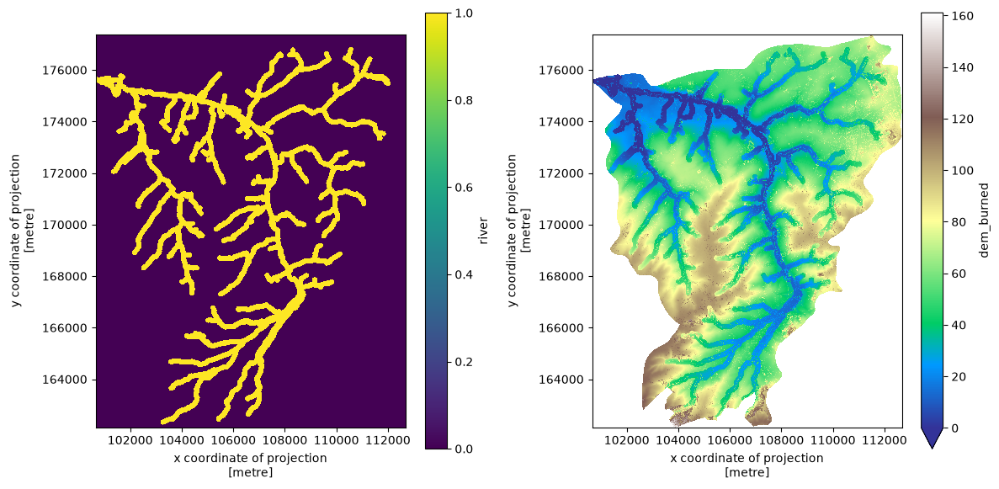

In [43]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 6))

ds_zwalm["river"].plot.imshow(ax=ax0)
ax0.axes.set_aspect('equal')

ds_zwalm["dem_burned"].plot.imshow(ax=ax1, cmap="terrain", vmin=0)
ax1.axes.set_aspect('equal')

fig.tight_layout()

## Let's practice!

For these exercises, a set of raster and vector datasets for the region of Ghent is available. Throughout the exercises, the goal is to map preferential locations to live given a set of conditions (certain level above sea-level, quiet and green neighbourhood, ..).

We start with the Digital Elevation Model (DEM) for Flanders. The data is available at https://overheid.vlaanderen.be/informatie-vlaanderen/producten-diensten/digitaal-hoogtemodel-dhmv, We downloaded the 25m resolution raster image, and provided a subset of this dataset as a zipped Tiff file in the course material.

<div class="alert alert-success">

**EXERCISE**:

* Read the DEM using `xarray`. The zip file is available at `data/gent/DHMVIIDTMRAS25m.zip`. You can either unzip the file, and use the path to the unzipped file, or prepend `zip://` to the path. 
* What is the CRS of this dataset?
* The dataset has a third dimension with a single band. This doesn't work for plotting, so create a new `DataArray` by selecting the single band. Assign the result to a variable `dem`.
* Make a quick plot of the dataset.

<details><summary>Hints</summary>

* Rasterio can directly read from a zip-file. If one wants read the file `./data/gent/FILENAME.zip`, add the `zip://.data/gent/FILENAME.zip` to read the zip file directly.
* The `crs` is an attribute, not a function, so no `()` required.
* Selecting in xarray is done with `sel`
* We will improve the plot in the following exercises, but as a quick solution, we already learnt about the `robust=True` plot option of xarray. 
* Just pick a color map that you like.

</details>   
    
</div>

In [44]:
dem = xr.open_dataarray("zip://./data/gent/DHMVIIDTMRAS25m.zip", engine="rasterio")
dem

<xarray.DataArray 'band_data' (band: 1, y: 1480, x: 1520)> Size: 9MB
[2249600 values with dtype=float32]
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 12kB 2.2e+05 2.2e+05 ... 1.83e+05 1.83e+05
  * x            (x) float64 12kB 8.701e+04 8.704e+04 ... 1.25e+05 1.25e+05
    spatial_ref  int64 8B ...
Attributes:
    STATISTICS_MAXIMUM:  354.7200012207
    STATISTICS_MEAN:     35.309165756095
    STATISTICS_MINIMUM:  -99.94034576416
    STATISTICS_STDDEV:   36.227290670867
    AREA_OR_POINT:       Area

In [45]:
dem.rio.crs

CRS.from_wkt('PROJCS["BD72 / Belgian Lambert 72",GEOGCS["BD72",DATUM["Reseau_National_Belge_1972",SPHEROID["International 1924",6378388,297,AUTHORITY["EPSG","7022"]],AUTHORITY["EPSG","6313"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4313"]],PROJECTION["Lambert_Conformal_Conic_2SP"],PARAMETER["latitude_of_origin",90],PARAMETER["central_meridian",4.36748666666667],PARAMETER["standard_parallel_1",51.1666672333333],PARAMETER["standard_parallel_2",49.8333339],PARAMETER["false_easting",150000.013],PARAMETER["false_northing",5400088.438],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","31370"]]')

In [46]:
dem = xr.open_dataarray("zip://./data/gent/DHMVIIDTMRAS25m.zip", engine="rasterio").sel(band=1)
dem

<xarray.DataArray 'band_data' (y: 1480, x: 1520)> Size: 9MB
[2249600 values with dtype=float32]
Coordinates:
  * y            (y) float64 12kB 2.2e+05 2.2e+05 ... 1.83e+05 1.83e+05
  * x            (x) float64 12kB 8.701e+04 8.704e+04 ... 1.25e+05 1.25e+05
    band         int64 8B 1
    spatial_ref  int64 8B ...
Attributes:
    STATISTICS_MAXIMUM:  354.7200012207
    STATISTICS_MEAN:     35.309165756095
    STATISTICS_MINIMUM:  -99.94034576416
    STATISTICS_STDDEV:   36.227290670867
    AREA_OR_POINT:       Area

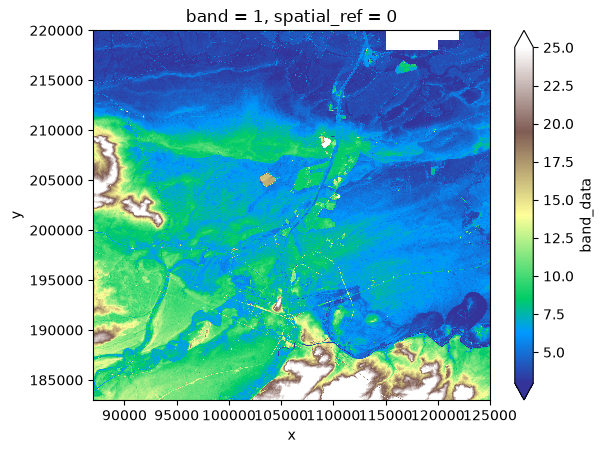

In [47]:
dem.plot.imshow(robust=True, cmap="terrain")

<div class="alert alert-success">

**EXERCISE**:

The dataset uses a large negative value to denote the "nodata" value (in this case meaning "outside of Flanders"). The NODATA value stored in the file metadata is - by default - read by xarray as `np.nan` (see notebook 11-xarray-intro.ipynb), but this behaviour can be excluded:
    
* Read the `zip://./data/gent/DHMVIIDTMRAS25m.zip"` file (band=1) without converting the NODATA value to `np.nan` (keep -9999.) and keeping the original data type.
* Check the value -9999. is used as "nodata" value.
* Repeat the plot from the previous exercise, but now set a fixed minimum value of 0 for the colorbar, to ignore the negative "nodata" in the color scheme.
* Replace the "nodata" value with `np.nan` using the `where()` method. 
    
<details><summary>Hints</summary>

* The `nodata` attribute is provided by the rioxarray package. Rioxarray loads this information from the geotiff file metadata and makes it available as `.rio.nodata`. 
* The `.rio.nodata` is a class attribute, not a function, so no `()` required.
* `vmin` and `vmax` define the colormap limits.
* `ẁhere` expects a condition (i.e. boolean values), e.g. `... != dem.rio.nodata`.
</details>   
    
</div>

In [48]:
dem = xr.open_dataarray("zip://./data/gent/DHMVIIDTMRAS25m.zip", engine="rasterio", mask_and_scale=False).sel(band=1)
dem.rio.nodata

np.float32(-9999.0)

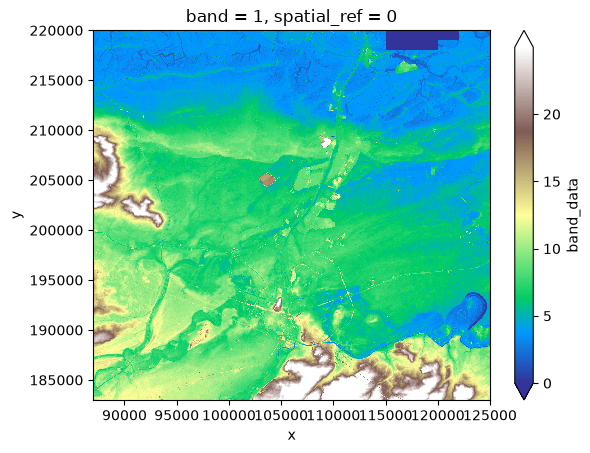

In [49]:
dem.plot.imshow(robust=True, vmin=0, cmap="terrain")

In [50]:
dem_masked = dem.where(dem != dem.rio.nodata)

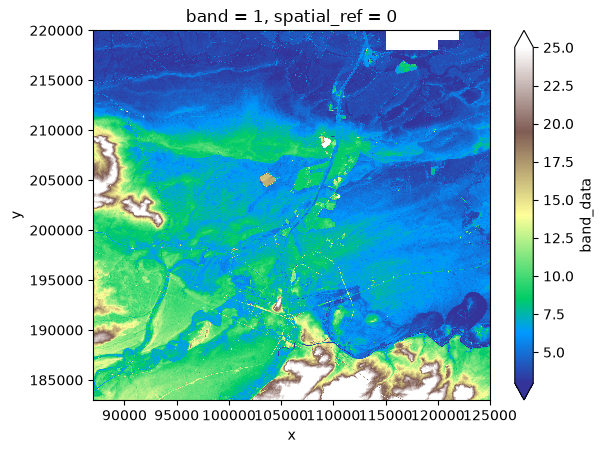

In [51]:
dem_masked.plot.imshow(robust=True, cmap="terrain")

__Remember__ Alternatively to masking the nodata value manually, you can do this explicitly when loading the data, using the `mask_and_scale=True` keyword (see also notebook [11-xarray-intro.ipynb](11-xarray-intro.ipynb)):

In [52]:
dem_masked = xr.open_dataarray("zip://./data/gent/DHMVIIDTMRAS25m.zip", engine="rasterio", mask_and_scale=True).sel(band=1)

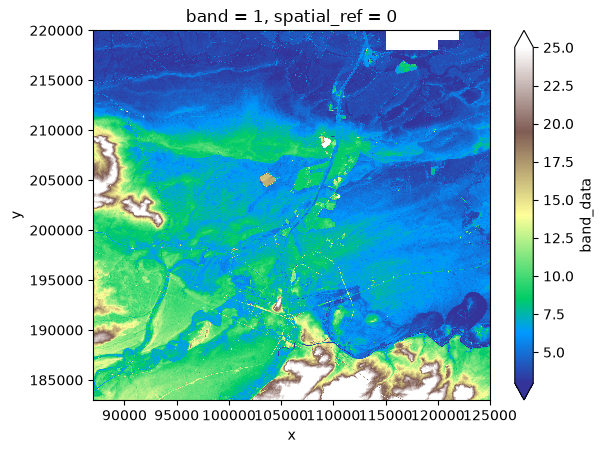

In [53]:
dem_masked.plot.imshow(robust=True, cmap="terrain")

<div class="alert alert-success">

**EXERCISE**:

We want to limit our search for locations to the surroundings of the centre of Ghent.

* Create a `Point` object for the centre of Ghent. Latitude/longitude coordinates for the Korenmarkt are: 51.05393, 3.72174
* We need our point in the same Coordinate Reference System as the DEM raster (i.e. EPSG:31370, or Belgian Lambert 72). Use GeoPandas to reproject the point:
    * Create a GeoSeries with this single point and specify its CRS with the `crs` keyword.
    * Reproject this series with the `to_crs` method. Assign the resulting GeoSeries to a variable `gent_centre_31370`.
* Calculcate a buffer of 10km radius around the point.
* Get the bounding box coordinates of this buffer. Assign this to `gent_bounds`.
    
<details><summary>Hints</summary>

* Remember the introduction on geospatial data and the shapely objects, e.g. `shapely.geometry.Point`?
* The Latitude/Longitude order is a typical gotcha. The `Point` expects `x` (longitude) as  first argument and `y` (latitude) as second argument.
* Use `geopandas.GeoSeries` to create a new GeoSeries and add the `crs` parameter. The lat/lon of the Kornmarkt are provided as EPSG:4326. 
* In EPSG:31370, the unit is meter, so make sure to use meter to define the buffer size.
* `.total_bounds` is a class attribute.

</details>   
    
</div>

In [54]:
from shapely import Point

In [55]:
gent_centre = Point(3.72174, 51.05393)

In [56]:
gent_centre_31370 = geopandas.GeoSeries([gent_centre], crs="EPSG:4326").to_crs("EPSG:31370")

In [57]:
gent_bounds = gent_centre_31370.buffer(10*1000).total_bounds
# or first extracting the Point again:
# gent_bounds = gent_centre_31370[0].buffer(10*1000).bounds
gent_bounds

array([ 94634.86315037, 183949.92234277, 114634.86315037, 203949.92234277])

<div class="alert alert-success">

**EXERCISE**:

With this bounding box, we can now clip a subset of the DEM raster for the area of interest. 
    
* Clip the `dem` raster layer. To clip with a bounding box instead of a geometry, you can use the `rio.clip_box()` method instead of `rio.clip()`.
* Make a plot. Use the "terrain" color map, and set the bounds of the color scale to 0 - 30.

<details><summary>Hints</summary>

* The `gent_bounds` is an array of 4 elements, whereas `clip_box` requires these as seperate input parameters... Did you know that in Python you can unpack these 4 values with the `*`: `*gent_bounds` will unpack to 4 individual input.

</details>   
    
</div>

In [58]:
dem_gent = dem.rio.clip_box(*gent_bounds)
dem_gent

<xarray.DataArray 'band_data' (y: 801, x: 801)> Size: 3MB
array([[ 7.36,  7.26,  7.07, ...,  5.12,  5.09,  5.16],
       [ 7.27,  7.01,  6.99, ...,  5.11,  5.18,  5.34],
       [ 6.93,  6.96,  7.02, ...,  5.38,  5.18,  5.22],
       ...,
       [11.51, 11.5 , 11.51, ..., 21.43, 20.89, 20.35],
       [11.4 , 11.51, 11.5 , ..., 21.36, 20.88, 20.19],
       [11.4 , 10.82, 13.57, ..., 21.19, 20.87, 20.58]],
      shape=(801, 801), dtype=float32)
Coordinates:
  * y            (y) float64 6kB 2.039e+05 2.039e+05 ... 1.84e+05 1.839e+05
  * x            (x) float64 6kB 9.464e+04 9.466e+04 ... 1.146e+05 1.146e+05
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    STATISTICS_MAXIMUM:  354.7200012207
    STATISTICS_MEAN:     35.309165756095
    STATISTICS_MINIMUM:  -99.94034576416
    STATISTICS_STDDEV:   36.227290670867
    AREA_OR_POINT:       Area
    scale_factor:        1.0
    add_offset:          0.0
    _FillValue:          -9999.0

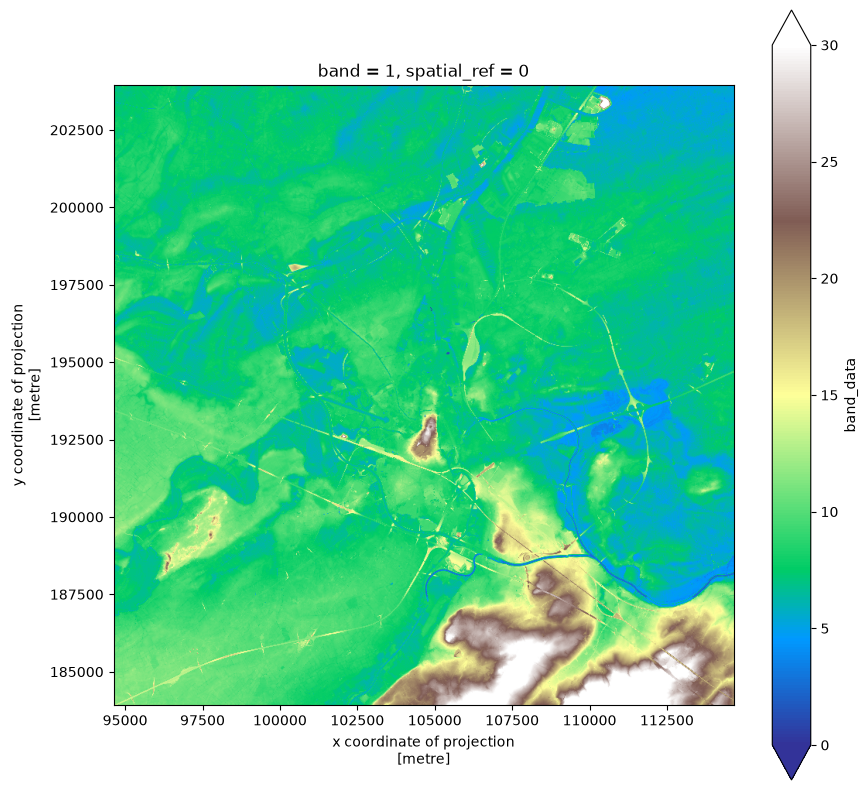

In [59]:
img = dem_gent.plot.imshow(
    cmap="terrain", figsize=(10, 10), interpolation='antialiased', vmin=0, vmax=30)
img.axes.set_aspect("equal")

The CORINE Land Cover (https://land.copernicus.eu/pan-european/corine-land-cover) is a program by the European Environment Agency (EEA) to provide an inventory of land cover in 44 classes of the European Union. The data is provided in both raster as vector format and with a resolution of 100m.

The data for the whole of Europe can be downloaded from the website (latest version: https://land.copernicus.eu/pan-european/corine-land-cover/clc2018?tab=download). This is however a large dataset, so we downloaded the raster file and cropped it to cover Flanders, and this subset is included in the repo as `data/CLC2018_V2020_20u1_flanders.tif` (the code to do this cropping can be see at [data/preprocess_data.ipynb#CORINE-Land-Cover](data/preprocess_data.ipynb#CORINE-Land-Cover)).

<div class="alert alert-success">

**EXERCISE**:

* Read the land use data provided as a tif (`data/CLC2018_V2020_20u1_flanders.tif`). Directly select the single band.
* Make a quick plot. The raster is using a negative value as "nodata", consider using the `robust=True` option.
* What is the resolution of this raster?
* What is the CRS?

<details><summary>Hints</summary>

* `rio.resolution()` is a method, so it requires the `()`.
* `rio.crs` is an attribute, so it does not require the `()`.

</details>   
    
</div>

In [60]:
land_use = xr.open_dataarray("data/CLC2018_V2020_20u1_flanders.tif").sel(band=1)
land_use

<xarray.DataArray 'band_data' (y: 1133, x: 2530)> Size: 11MB
[2866490 values with dtype=float32]
Coordinates:
  * y            (y) float64 9kB 3.178e+06 3.178e+06 ... 3.065e+06 3.065e+06
  * x            (x) float64 20kB 3.79e+06 3.79e+06 ... 4.042e+06 4.042e+06
    band         int64 8B 1
    spatial_ref  int64 8B ...
Attributes:
    AREA_OR_POINT:  Area

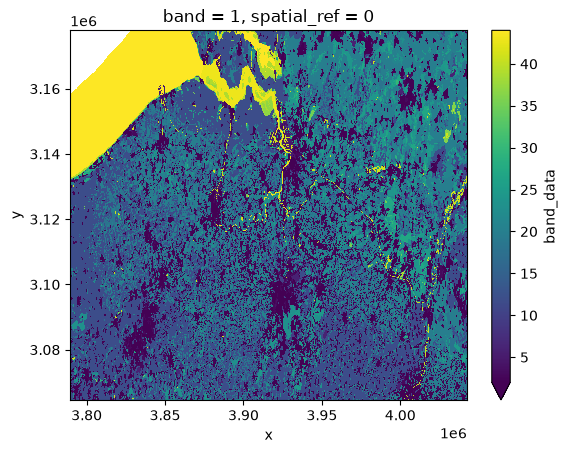

In [61]:
land_use.plot.imshow(robust=True)

In [62]:
land_use.rio.resolution()

(100.0, -100.0)

In [63]:
land_use.rio.crs

CRS.from_wkt('PROJCS["ETRS89-extended / LAEA Europe",GEOGCS["ETRS89",DATUM["European_Terrestrial_Reference_System_1989",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6258"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4258"]],PROJECTION["Lambert_Azimuthal_Equal_Area"],PARAMETER["latitude_of_center",52],PARAMETER["longitude_of_center",10],PARAMETER["false_easting",4321000],PARAMETER["false_northing",3210000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Northing",NORTH],AXIS["Easting",EAST],AUTHORITY["EPSG","3035"]]')

<div class="alert alert-success">

**EXERCISE**:

The land use dataset is a European dataset and uses a Europe-wide projected CRS (https://epsg.io/3035).

* Reproject the land use raster to the same CRS as the DEM raster (EPSG:31370), and plot the result.

<details><summary>Hints</summary>

* For the sake of the exercise, pick any resampling algorithm or just the default option.

</details>   
    
</div>

In [64]:
land_use_reprojected = land_use.rio.reproject(dem_gent.rio.crs)
land_use_reprojected

<xarray.DataArray 'band_data' (y: 1324, x: 2610)> Size: 14MB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]],
      shape=(1324, 2610), dtype=float32)
Coordinates:
  * y            (y) float64 11kB 2.604e+05 2.603e+05 ... 1.282e+05 1.281e+05
  * x            (x) float64 21kB 8.802e+03 8.902e+03 ... 2.697e+05 2.698e+05
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area

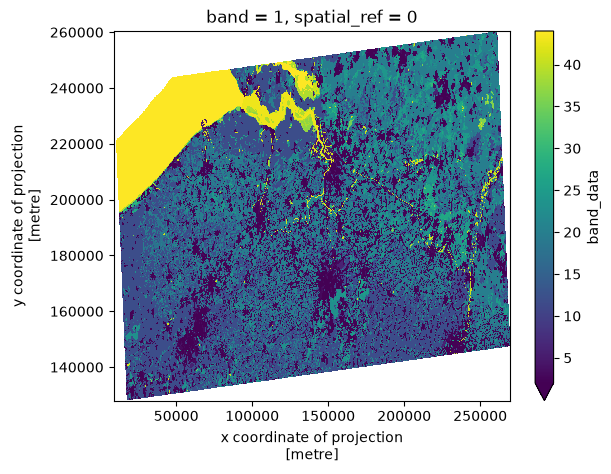

In [65]:
land_use_reprojected.plot.imshow(robust=True)

<div class="alert alert-success">

**EXERCISE**:

In addition to reprojecting to a new CRS, we also want to upsample the land use dataset to the same resolution as the DEM raster, and to use the exact same grid layout, so we can compare and combine those rasters pixel-by-pixel.

Such a reprojection can be done with the `reproject()` method by providing the target geospatial "transform" (which has the information for the bounds and resolution) and shape for the result. `rioxarray` provides a short-cut for this operation with the `reproject_match()` method, to reproject one raster to the CRS, extent and resolution of another raster.  

* Reproject the land use raster to the same CRS and extent as the DEM subset for Ghent (`dem_gent`). Call the result `land_use_gent`.
* Make a plot of the result.

<details><summary>Hints</summary>

* Check the help of the `.rio.reproject_match` method (SHIFT + TAB) to know which input ou need. For the sake of the exercise, pick any resampling algorithm or just the default (nearest) option.
* The data calling the method is being transformed, and the input parameter is the target to match.

</details>   
    
</div>

In [66]:
land_use_gent = land_use.rio.reproject_match(dem_gent)

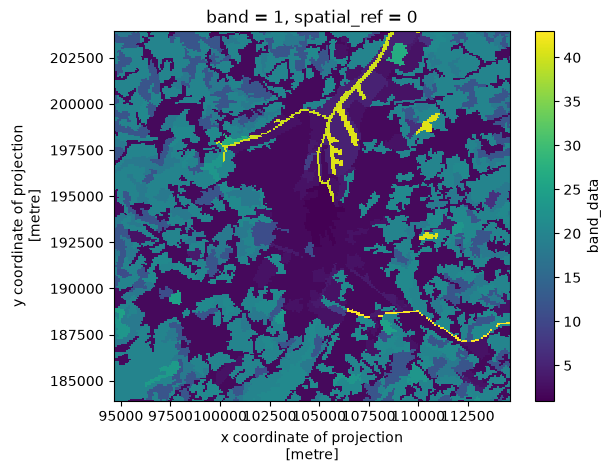

In [67]:
land_use_gent.plot.imshow()

The land use dataset is a raster with discrete values (i.e. different land use classes). The [CurieuzeNeuzen case study](case-curieuzeneuzen-air-quality.ipynb#Combining-with-Land-Use-data) goes into more depth on those values, but for this exercise it is sufficient to know that values 1 and 2 are the Continuous and Discontinuous urban fabric (residential areas).

<div class="alert alert-success">

**EXERCISE**:

Let's find the preferential locations to live, assuming we want to be future-proof and live at least 10m above sea level in a residential area.

* Create a new array denoting the residential areas (where `land_use_gent` is equal to 1 or 2). Call this `land_use_residential`, and make a quick plot.
* Plot those locations that are 10m above sea-level.
* Combine the residential areas and areas > 10m in a single array called `suitable_locations`, and plot the result.
    
<details><summary>Hints</summary>

* To select for multiple options, one can either combine multiple conditions using `|` (or) or us the `isin([...,...])` option, both will do.
* The output of a condition is a Boolean map that can be plot just like other maps, e.g. `(dem_gent > 10).plot.imshow()`.
* Fo the `suitable_locations`, both boolean conditions need to be True, so combine them with either `&` or just multiply them with `*`.

</details>   
    
</div>

In [68]:
land_use_residential = (land_use_gent == 1) | (land_use_gent == 2)
land_use_residential

<xarray.DataArray 'band_data' (y: 801, x: 801)> Size: 642kB
array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]], shape=(801, 801))
Coordinates:
  * y            (y) float64 6kB 2.039e+05 2.039e+05 ... 1.84e+05 1.839e+05
  * x            (x) float64 6kB 9.464e+04 9.466e+04 ... 1.146e+05 1.146e+05
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area

In [69]:
# Alternative solution using `isin`
land_use_residential = land_use_gent.isin([1, 2])
land_use_residential

<xarray.DataArray 'band_data' (y: 801, x: 801)> Size: 642kB
array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]], shape=(801, 801))
Coordinates:
  * y            (y) float64 6kB 2.039e+05 2.039e+05 ... 1.84e+05 1.839e+05
  * x            (x) float64 6kB 9.464e+04 9.466e+04 ... 1.146e+05 1.146e+05
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area

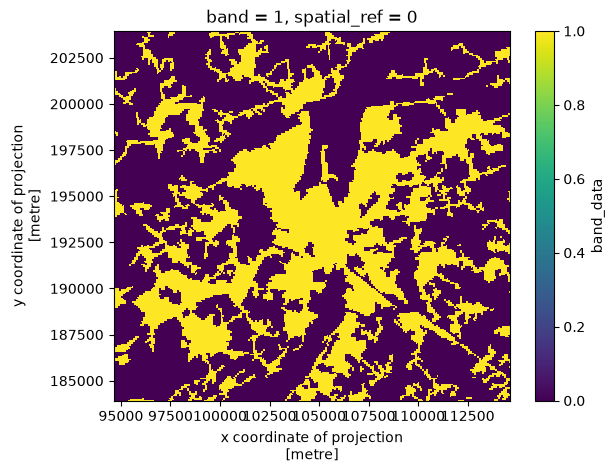

In [70]:
land_use_residential.plot.imshow()

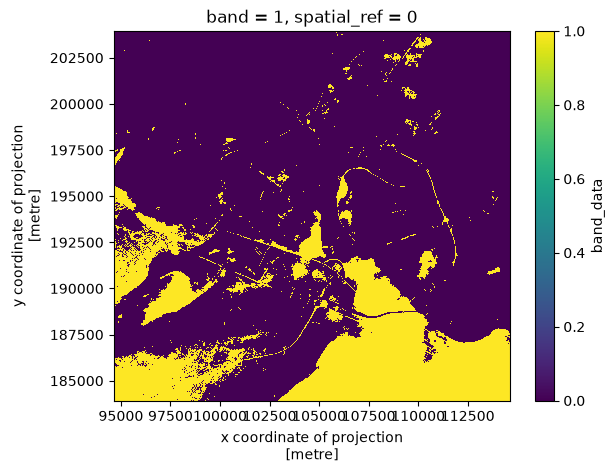

In [71]:
(dem_gent > 10).plot.imshow()

In [72]:
suitable_locations = land_use_residential * (dem_gent > 10)

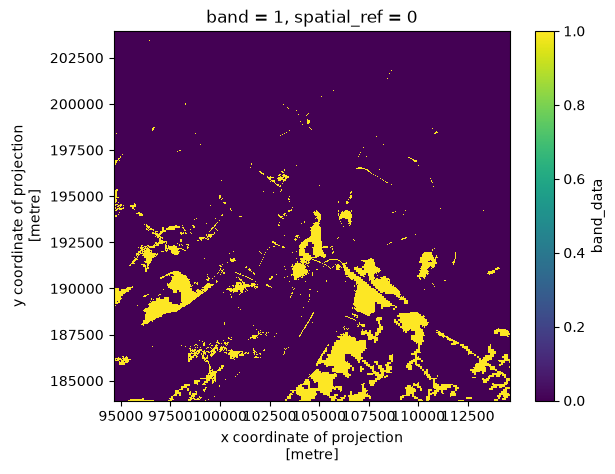

In [73]:
suitable_locations.plot.imshow()

<div class="alert alert-success">

**EXERCISE**:

In addition to the previous conditions, assume we also don't want to live close to major roads.

We downloaded the road segments open data from Ghent (https://data.stad.gent/explore/dataset/wegsegmenten-gent/) as a GeoJSON file, and provided this in the course materials: `/data/gent/vector/wegsegmenten-gent.geojson.zip`
    
* Read the GeoJSON road segments file into a variable `roads` and check the first few rows.
* The column "frc_omschrijving" contains a description of the type of road for each segment. Get an overview of the available segments and types by doing a "value counts" of this column.

<details><summary>Hints</summary>

* GeoPandas does NOT need the `zip://...` to read in zip files.
* The first few rows are also the `head` of a data set.
* The `value_counts` provides the number of records for each of the different values in a column.

</details>   
    
</div>

In [74]:
roads = geopandas.read_file("./data/gent/vector/wegsegmenten-gent.geojson.zip")

In [75]:
roads.head()

,objectid,wegsegid,aanmaakdat,aanlegjaar,voorlopige_oplevering,definitieve_oplevering,straatnaam,pcode_rechts,pcode_links,routenr,...,s,t,o,p,aanlegjaar_getal,frc_omschrijving,synckey,syncdate,geo_point_2d,geometry
0,5631534,WEGO007282,2008-10-14 22:00:00+00:00,1950,None,None,Hamerstraat,9000,9000,NaN,...,0.0,0.0,0.0,0.0,1950.0,Local Road,GWR.wegsegmenten.inf/wegseg007282,2024-01-29 08:13:28+00:00,"{'lon': 3.6978443588888914, 'lat': 51.06428121...","LINESTRING (3.69791 51.0643, 3.69778 51.06427)"
1,5631541,WEGO003582,NaT,NaN,None,None,Langestraat,9050,9050,NaN,...,0.0,0.0,0.0,0.0,NaN,Local Road,GWR.wegsegmenten.inf/wegseg003582,2024-01-29 08:13:28+00:00,"{'lon': 3.7448342931937644, 'lat': 51.03857058...","LINESTRING (3.74479 51.03842, 3.74488 51.03872)"
2,5631544,WEGO009006,NaT,NaN,None,None,Cliviastraat,9000,9000,NaN,...,0.0,0.0,0.0,0.0,NaN,Local Road of Minor Importance,GWR.wegsegmenten.inf/wegseg009006,2024-01-29 08:13:28+00:00,"{'lon': 3.7045183974899025, 'lat': 51.07401603...","LINESTRING (3.70492 51.07445, 3.70477 51.07435..."
3,5631545,WEGO014327,2011-10-18 22:00:00+00:00,1950,None,None,Antwerpsesteenweg,9040,9040,N70a,...,0.0,0.0,0.0,0.0,1950.0,Secondary Road,GWR.wegsegmenten.inf/wegseg014327,2024-01-29 08:13:28+00:00,"{'lon': 3.7558717393844745, 'lat': 51.06617789...","LINESTRING (3.75624 51.06623, 3.75603 51.0662,..."
4,5631546,WEGO009746,2008-09-21 22:00:00+00:00,1950,None,None,Botestraat,9032,9032,NaN,...,0.0,0.0,0.0,0.0,1950.0,Local Connecting Road,GWR.wegsegmenten.inf/wegseg009746,2024-01-29 08:13:28+00:00,"{'lon': 3.695220066501279, 'lat': 51.083797361...","LINESTRING (3.69489 51.08366, 3.69555 51.08393)"


In [76]:
roads["frc_omschrijving"].value_counts()

frc_omschrijving
Local Road of Minor Importance               4852
Local Road                                   4432
Path                                         2131
Local Connecting Road                        1131
Other Major Road                              779
Local Road of High Importance                 685
Secondary Road                                340
Other Road                                    204
Major Road Less Important than a Motorway     190
Motorway, Freeway or Other Major Road         102
Private roads                                  83
Name: count, dtype: int64

<div class="alert alert-success">

**EXERCISE**:

We are interested in the big roads, as these are the ones we want to avoid: "Motorway or Freeway", "Major Road" and "Other Major Road".

* Filter the `roads` table based on the provided list of road types: select those rows where the "frc_omschrijving" column is equal to one of those values, and call this `roads_subset`.
* Make a quick plot of this subset and use the "frc_omschrijving" colum to color the lines.

<details><summary>Hints</summary>

* Selecting multiple options at the same time is most convenient with the `isin()` method.
* Use the GeoPandas `.plot` method and specifh the `frc_omschrijving` column to the `column` parameter.

</details>   
    
</div>

In [77]:
road_types = [
    "Motorway, Freeway or Other Major Road",
    "Major Road Less Important than a Motorway",
    "Other Major Road",
]

In [78]:
roads_subset = roads[roads["frc_omschrijving"].isin(road_types)]

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

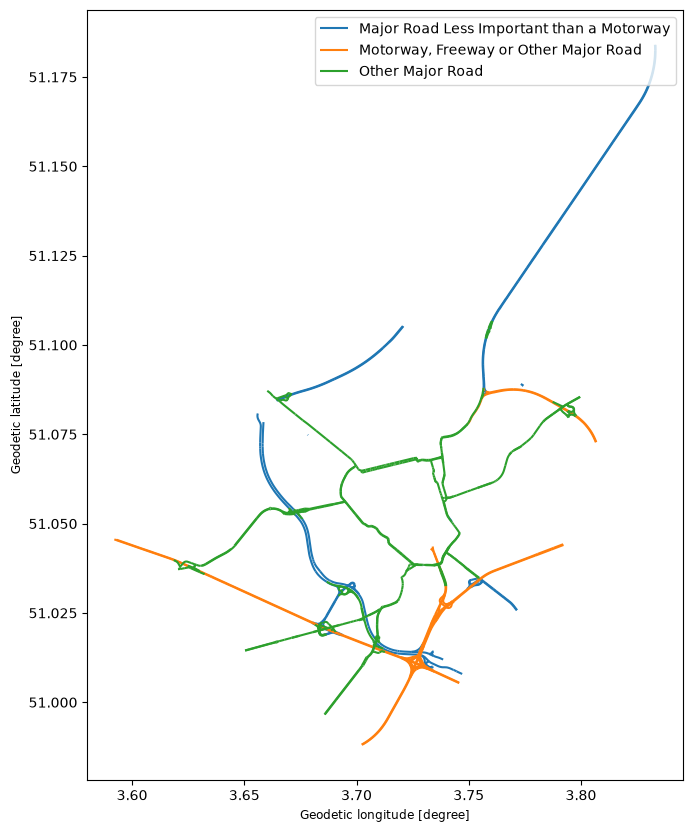

In [79]:
roads_subset.plot(column="frc_omschrijving", figsize=(10, 10), legend=True)

<div class="alert alert-success">

**EXERCISE**:

Before we convert the vector data to a raster, we want to buffer the roads. We will use a larger buffer radius for the larger roads.

* Using the defined `buffer_per_roadtype` dictionary, create a new Series by mapping the values in the "frc_omschrijving" column to the matching buffer radius.
* Convert the `roads_subset` GeoDataFrame to CRS `EPSG:31370`, and create buffered lines (polygons) with the calculated buffer radius distances. Call the result `roads_buffer`.
    
<details><summary>Hints</summary>

* Use the `map()` method to map the values using the provided dictionary `buffer_per_roadtype`.
* The conversion to EPSG:31370 is important to be able to work with the meters to define the buffer size.
* The `buffer` method can take a single value to apply to all values, but also a Series of values, with a buffer size defined for each element.

</details>   
    
</div>

In [80]:
buffer_per_roadtype = {
    "Motorway, Freeway or Other Major Road": 750,
    "Major Road Less Important than a Motorway": 500,
    "Other Major Road": 150,
}

In [81]:
buffers = roads_subset["frc_omschrijving"].map(buffer_per_roadtype)
buffers

10       500
11       750
21       150
25       150
28       500
        ... 
14856    750
14867    150
14889    150
14909    150
14925    500
Name: frc_omschrijving, Length: 1071, dtype: int64

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

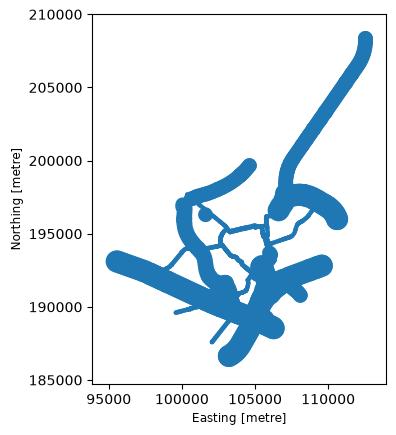

In [82]:
roads_buffer = roads_subset.to_crs("EPSG:31370").buffer(buffers)
roads_buffer.plot()

<div class="alert alert-success">

**EXERCISE**:

Convert the buffered road segments to a raster:
    
* Use `features.features.rasterize()` to convert the `roads_buffer` GeoDataFrame to a raster:
    * Pass the geometry column as the first argument.
    * Pass the shape and transform of the `dem_gent` to specify the desired spatial extent and resolution of the output raster.
* Invert the values of the raster by doing `1 - arr`, and plot the array with `plt.imshow(..)`.
* Recalculate the `suitable_locations` variable, using 1/ land_use_residential, 2/ dem > 10 and 3/ outside the road buffers.  
    
<details><summary>Hints</summary>

* Access the geometry column using the `.geometry` attribute.
* `shape` is also an attribute.
* `.rio.transform()` is a method, so it requires the `()`.
* Previously, suitable locations were `land_use_residential * (dem_gent > 10)`. Combine this with the `(1 - roads_buffer_arr)` output.

</details>   
    
</div>

In [83]:
import rasterio.features

In [84]:
roads_buffer_arr = rasterio.features.rasterize(
    roads_buffer.geometry, 
    out_shape=dem_gent.shape, 
    transform=dem_gent.rio.transform())

In [85]:
1 - roads_buffer_arr

array([[1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       ...,
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1]], shape=(801, 801))

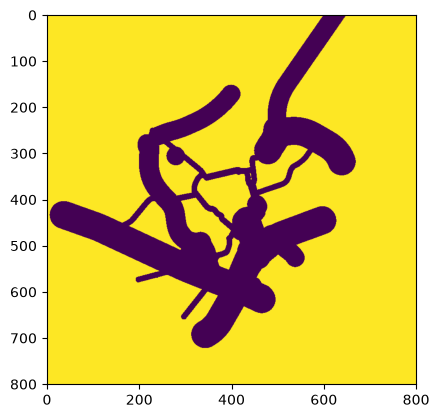

In [86]:
plt.imshow(1 - roads_buffer_arr)

In [87]:
suitable_locations = land_use_residential * (dem_gent > 10) * (1 - roads_buffer_arr)

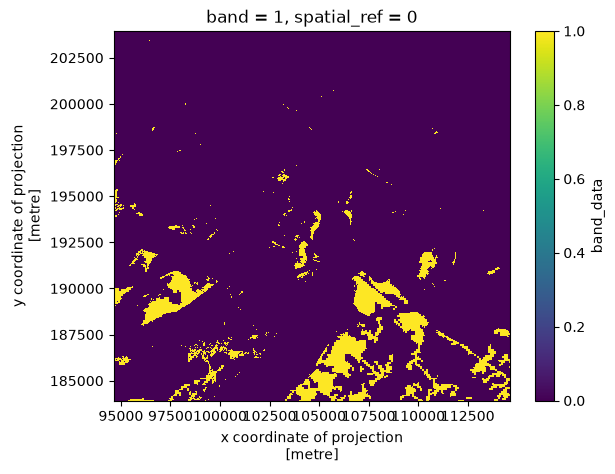

In [88]:
suitable_locations.plot.imshow()

<div class="alert alert-success">

**EXERCISE**:

Make a plot with a background map of the selected locations. 
    
* Plot the provided `gent` GeoDataFrame (a single row table with the are of the Ghent municipality). Use a low "alpha" to give it a light color.
* Add a background map using contextily.
* Plot the `suitable_locations` raster on top of this figure: first mask the array to select only those values larger than zero (so the other values becomes NaN, and are not plotted). Then plot the result, adding it to the existing figure using the `ax` keyword.

<details><summary>Hints</summary>

* The `fig, ax = plt.subplots(figsize=(15, 15))` is a convenient shortcut to prepare a Matplotlib Figure and Axes. 
* Make sure to define the `crs="EPSG:31370"` for contextily.
* `where(...)` is a powerfull way to exclude data as it - by default - adds NaN values for piels where the condition is not True.
</details>   
    
</div>

In [89]:
import contextily

In [90]:
gent = geopandas.read_file("data/gent/vector/gent.geojson")

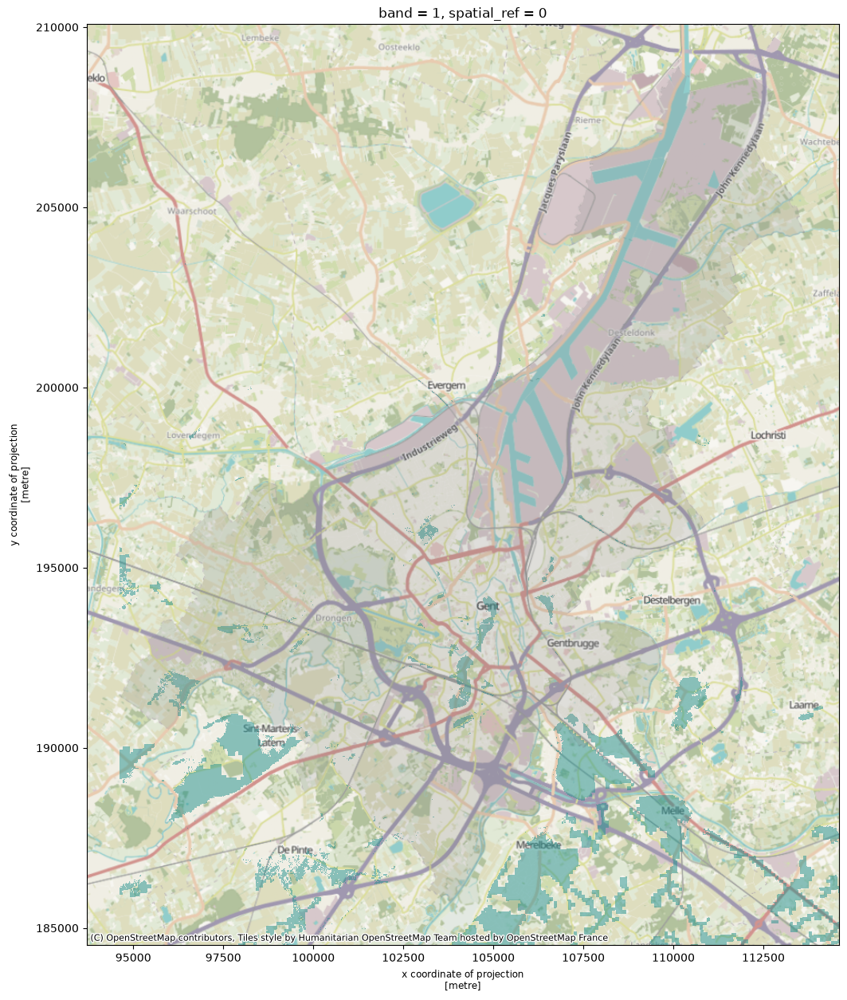

In [91]:
fig, ax = plt.subplots(figsize=(15, 15))

gent.to_crs("EPSG:31370").plot(ax=ax, alpha=0.2, color="grey")
contextily.add_basemap(ax, crs="EPSG:31370")

suitable_locations.where(suitable_locations > 0).plot.imshow(ax=ax, alpha=0.5, add_colorbar=False)
ax.set_aspect("equal")

## Advanced (optional) exercises:

<div class="alert alert-success">

**EXERCISE**:

We downloaded the data about urban green areas in Ghent (https://data.stad.gent/explore/dataset/parken-gent).

* Read in the data at `data/gent/vector/parken-gent.geojson` into a variable `green`.
* Check the content (first rows, quick plot)
* Remove the rows with an empty geometry (`None`)    
* Convert this vector layer to a raster using the spatial extent and resolution of `dem_gent` as the targer raster.
* The `rasterio.features.rasterize` results in a numpy array. Convert this to a DataArray using the `xr.DataArray(..)` constructor, specifying the coordinates of `dem_gent` (`dem_gent.coords`) for the coordinates of the new array.
    
</div>

In [92]:
green = geopandas.read_file("data/gent/vector/parken-gent.geojson")
green.head()

,status,fiche_id,functies,globalid,naam,urid,gentid,geo_point_2d,label_id,statusnaam,code_jd,geometry
0,2,NaN,groen met historische waarde,5a5d5be1-16df-4349-96a7-41f2d6bec611,Tuin Villa Voortman,wel/vecpark445,NaN,"[51.064736, 3.721617]",NaN,in uitvoering,NaN,"POLYGON ((3.72144 51.06534, 3.7214 51.06533, 3..."
1,3,NaN,natuur,3320522b-0bfc-4289-a52a-0ee3150ee664,Volkstuinen Boerse Poort,wel/vecpark455,NaN,"[51.056945, 3.687477]",NaN,uitgevoerd,NaN,"POLYGON ((3.68856 51.05741, 3.68834 51.05759, ..."
2,3,NaN,natuur,834f7f14-b65d-4276-a261-df5a0aefa47b,Koppelingsgebied Desteldonk,wel/vecpark456,NaN,"[51.124702, 3.78963]",NaN,uitgevoerd,NaN,"POLYGON ((3.78747 51.12485, 3.78692 51.1249, 3..."
3,3,NaN,"natuur, bos",82a65128-5f5d-489c-9a3e-657810dff29a,Koppelingsgebied Doornzele Noord,wel/vecpark459,NaN,"[51.147042, 3.767326]",NaN,uitgevoerd,NaN,"POLYGON ((3.76543 51.14573, 3.76542 51.14575, ..."
4,3,NaN,NaN,bcfa5ae0-90f5-408b-bc1d-1758bdd0d42d,Emile Braunplein,wel/vecpark460,GRO227,"[51.053824, 3.723985]",NaN,uitgevoerd,NaN,"MULTIPOLYGON (((3.72413 51.05391, 3.72412 51.0..."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

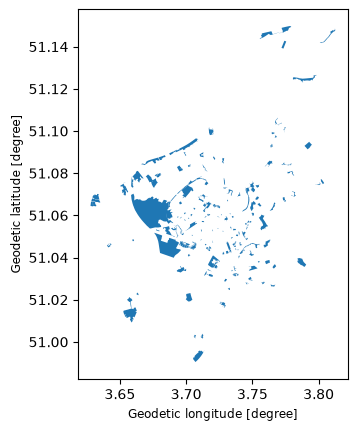

In [93]:
green.plot()

In [94]:
green = green.dropna(subset="geometry")

In [95]:
import rasterio.features

green_arr = rasterio.features.rasterize(
    green.to_crs("EPSG:31370").geometry, 
    out_shape=dem_gent.shape, 
    transform=dem_gent.rio.transform())

In [96]:
green_arr = xr.DataArray(green_arr, coords=dem_gent.coords)

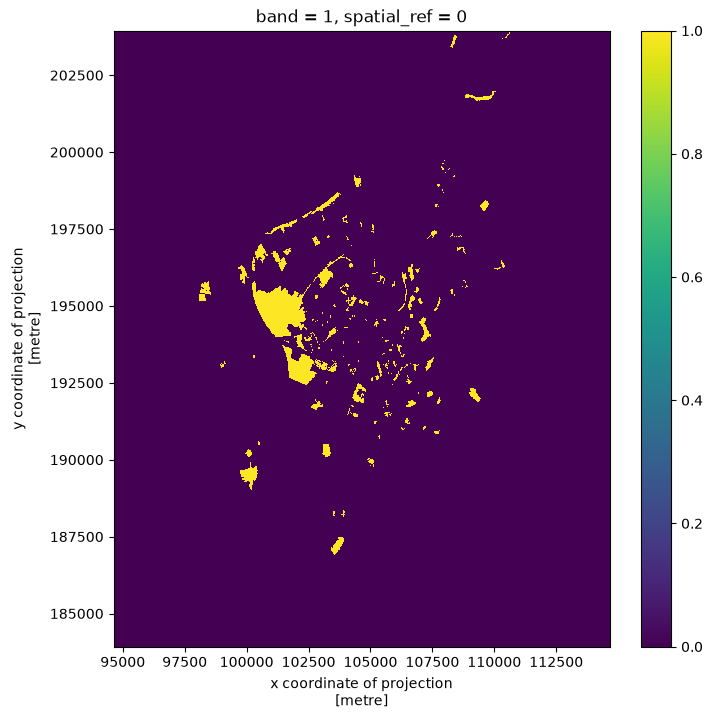

In [97]:
green_arr.plot.imshow(figsize=(8, 8))

<div class="alert alert-success">

**EXERCISE**:

For the urban green areas, we want to calculate a statistic for a neighbourhood around each pixel ("focal" statistics). This can be expressed as a convolution with a defined kernel.    

The [xarray-spatial](https://xarray-spatial.org/index.html) package includes functionality for such focal statistics and convolutions.

* Use the `focal.focal_stats()` function from xarray-spatial to calculate the sum of green are in a neighborhood of 500m around each point. Check the help of this function to see which arguments to specify.
* Make a plot of the resulting `green_area` array.
    
</div>

In [98]:
from xrspatial import focal, convolution

In [99]:
x, y = convolution.calc_cellsize(green_arr)

In [100]:
kernel = convolution.circle_kernel(x, y, 500)

In [101]:
green_area = focal.focal_stats(green_arr, kernel, stats_funcs=["sum"])

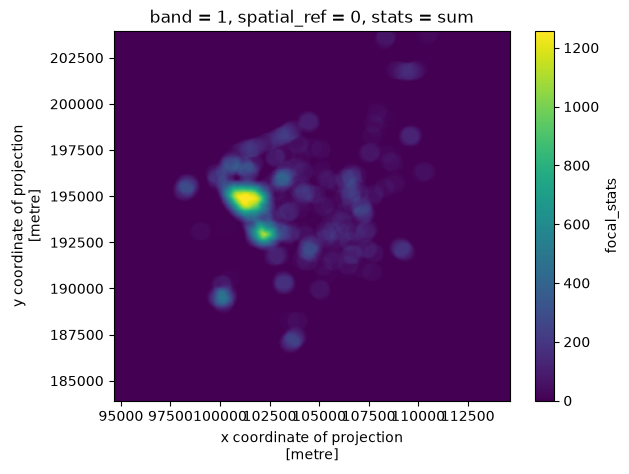

In [102]:
green_area.sel(stats="sum").plot.imshow()

The `scipy` package also provides optimized convolution algorithms. In case of the "sum" statistic, this is equivalent:

In [103]:
from scipy import signal

In [104]:
green_area_arr = signal.convolve(green_arr, kernel, mode='same')

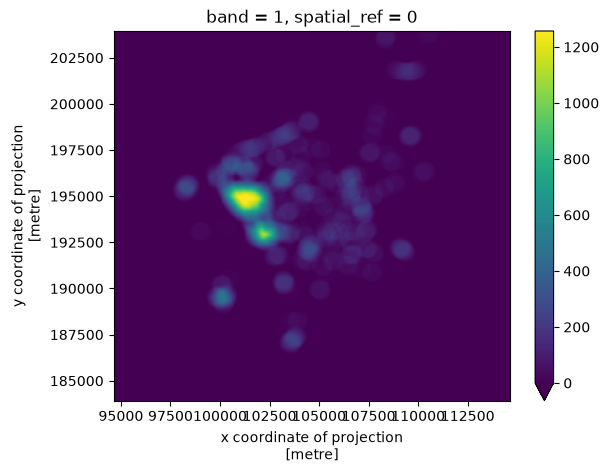

In [105]:
xr.DataArray(green_area_arr, coords=dem_gent.coords).plot.imshow(vmin=0)

<div class="alert alert-success">

**EXERCISE**:

Make a plot with a background map of the selected locations, i.e. land_use_residential, dem > 10, outside road buffers and 'sufficient'as green area. 
    
Define sufficient green area as the `green_area` pixels where the sum of the convolution (previous exercise) is larger as 10 (keep those values and convert pixels with values lower than 10 to 0 values). Multiply the different conditions/categories, so the green area score is included in the final result.
    
</div>

In [106]:
green_area10 = green_area.sel(stats="sum").where(green_area.sel(stats="sum") > 10, 0)

In [107]:
suitable_locations = land_use_residential * (dem_gent > 10) * (1 - roads_buffer_arr) * green_area10

In [108]:
import contextily

In [109]:
gent = geopandas.read_file("data/gent/vector/gent.geojson")

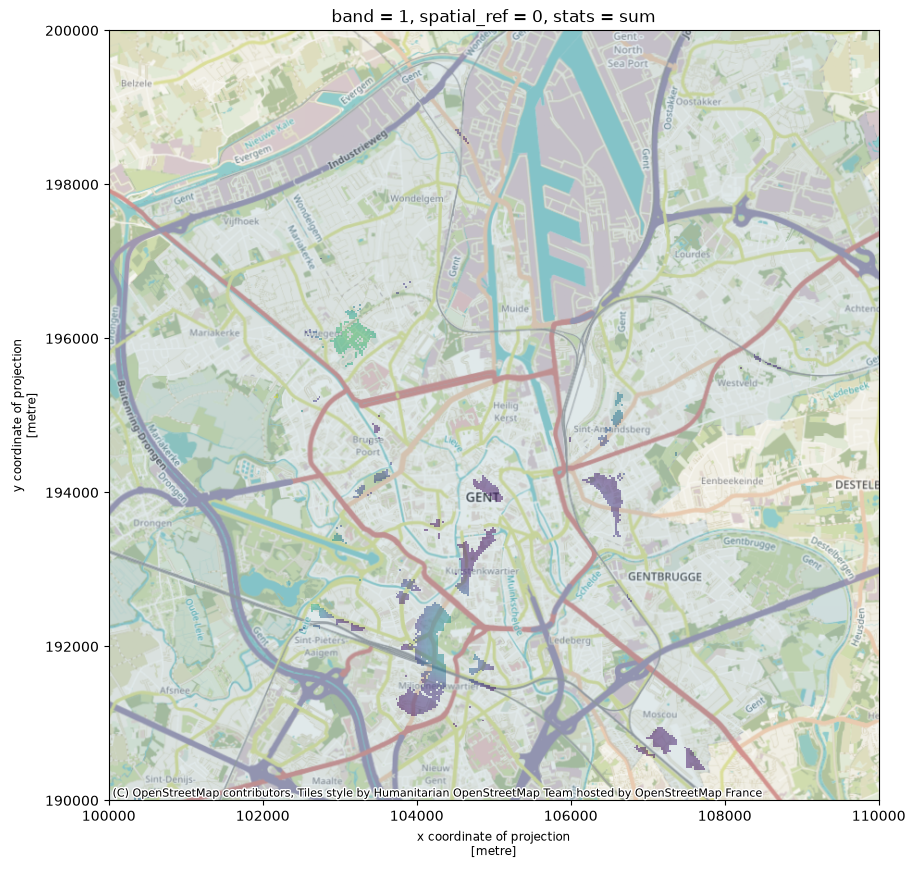

In [117]:
fig, ax = plt.subplots(figsize=(10, 10))
gent.to_crs("EPSG:31370").plot(ax=ax, alpha=0.1)
ax.set(ylim=(190_000, 200_000), xlim=(100_000, 110_000))
contextily.add_basemap(ax, crs="EPSG:31370")

suitable_locations.where(suitable_locations>0).plot.imshow(ax=ax, alpha=0.5, add_colorbar=False)
ax.set_aspect("equal")

# Extracting values from rasters based on vector data

The **exactextract** package provides methods to calculate summary statistics of geospatial raster datasets based on vector geometries (https://github.com/isciences/exactextract / https://isciences.github.io/exactextract/).

<div class="alert alert-warning">

**! Manual download needed !** <br>

The data can be downloaded from the NOAA at [download link](https://www.ngdc.noaa.gov/mgg/global/relief/ETOPO5/TOPO/ETOPO5/ETOPO5.DAT) and save the file in the `data` subdirectory. The file will be available in the subdirectory `data/ETOPO5.DAT`, next to an already provided `data/etopo5.vrt` file that translates the custom `.DAT` format into a rasterio/DGDAL-readable raster.

</div>

To illustrate this, we are reading a raster file with elevation data of the full world (the file contains a single band for the elevation:

In [2]:
countries = geopandas.read_file("./data/ne_110m_admin_0_countries.zip")
cities = geopandas.read_file("./data/ne_110m_populated_places.zip")

In [3]:
# Use GDAL to match longitudes currently on 0–360 (bounds −0.04 to 359.96) instead of −180 to 180 as used by the overlays country and city data.
!gdal raster reproject --config CENTER_LONG=0 --dst-crs EPSG:4326 --bbox -180,-90,180,90 data/etopo5.vrt data/etopo5.tif --overwrite

0...10...20...30...40...50...60...70...80...90...100 - done.


In [4]:
dem_geotiff = "data/etopo5.tif"

In [5]:
xr.open_dataarray(dem_geotiff).sel(band=1)

<xarray.DataArray 'band_data' (y: 2160, x: 4320)> Size: 37MB
[9331200 values with dtype=float32]
Coordinates:
  * y            (y) float64 17kB 89.96 89.88 89.79 ... -89.79 -89.87 -89.96
  * x            (x) float64 35kB -180.0 -179.9 -179.8 ... 179.8 179.9 180.0
    band         int64 8B 1
    spatial_ref  int64 8B ...
Attributes:
    AREA_OR_POINT:  Area

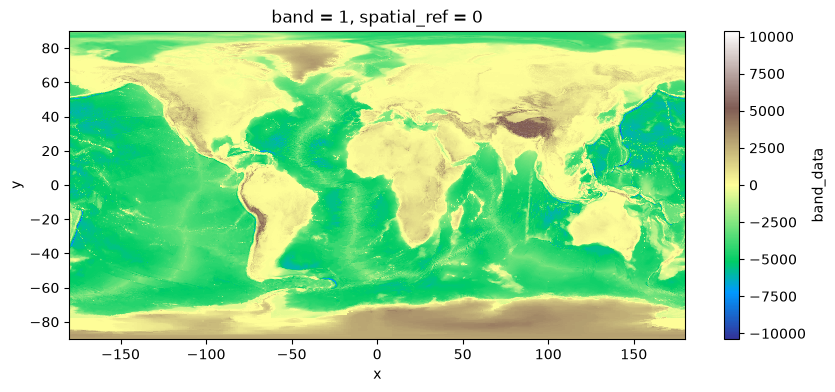

In [6]:
img = xr.open_dataarray(dem_geotiff).sel(band=1).plot.imshow(cmap="terrain", figsize=(10, 4), )
img.axes.set_aspect("equal")

Given this raster of the elevation, we might want to know the elevation at a certain location or for each country.
For the countries example, we want to extract the pixel values that fall within a country polygon, and calculate a statistic for it, such as the mean or the maximum.

Such functionality to extract information from a raster for given vector data is provided by the exactextract package.

In [7]:
from exactextract import exact_extract

For extracting the pixel values for polygons, we use the `exact_extract` function, passing it the raster, the GeoDataFrame, and the statistics to compute. Contrary to a regular pixel-center approach, `exactextract` takes the fraction of each pixel covered by the polygon into account.

In [8]:
dem = xr.open_dataarray(dem_geotiff).sel(band=1).rio.write_nodata(-999)
result = exact_extract(dem, countries, ['min', 'mean', 'max'], output="pandas")

The results can be assigned to new columns:

In [9]:
countries[['min', 'max', 'mean']] = result

In [10]:
countries.head()

,iso_a3,name,continent,pop_est,gdp_md_est,geometry,min,max,mean
0,AFG,Afghanistan,Asia,34124811.0,64080.0,"POLYGON ((61.21082 35.65007, 62.23065 35.27066...",244.0,1890.563132,5699.0
1,AGO,Angola,Africa,29310273.0,189000.0,"MULTIPOLYGON (((23.90415 -11.72228, 24.07991 -...",-994.0,1084.287140,2103.0
2,ALB,Albania,Europe,3047987.0,33900.0,"POLYGON ((21.02004 40.84273, 20.99999 40.58, 2...",-656.0,768.439617,2138.0
3,ARE,United Arab Emirates,Asia,6072475.0,667200.0,"POLYGON ((51.57952 24.2455, 51.75744 24.29407,...",-52.0,130.016628,1524.0
4,ARG,Argentina,South America,44293293.0,879400.0,"MULTIPOLYGON (((-66.95992 -54.89681, -67.56244...",-989.0,624.517811,5257.0


And then we can sort by the average elevation of the country:

In [11]:
countries.sort_values('mean', ascending=False).head()

,iso_a3,name,continent,pop_est,gdp_md_est,geometry,min,max,mean
122,PAK,Pakistan,Asia,2.049249e+08,988200.0,"POLYGON ((60.87425 29.82924, 62.54986 29.31857...",-181.0,1036.548529,7833.0
30,CHN,China,Asia,1.379303e+09,21140000.0,"MULTIPOLYGON (((75.15803 37.13303, 74.98 37.41...",-67.0,1832.019846,7315.0
119,NPL,Nepal,Asia,2.938430e+07,71520.0,"POLYGON ((81.11126 30.18348, 81.5258 30.42272,...",61.0,2241.580238,6705.0
157,TJK,Tajikistan,Asia,8.468555e+06,25810.0,"POLYGON ((74.98 37.41999, 73.9487 37.42157, 73...",320.0,3118.231865,6096.0
85,KGZ,Kyrgyzstan,Asia,5.789122e+06,21010.0,"POLYGON ((80.25999 42.35, 80.11943 42.12394, 7...",594.0,2959.580315,6096.0


For points, we can directly use xarray instead. Elevation is a continuous variable, so we interpolate the raster (bilinear by default) at the point locations with `interp()`. Passing the coordinates as `DataArray`s sharing a common dimension (here `point`) makes xarray select pointwise (one value per city) instead of returning a grid of all x/y combinations.

See https://docs.xarray.dev/en/latest/user-guide/interpolation.html#advanced-interpolation.

__Note__ For discrete data (e.g. land cover classes), interpolating makes no sense. Use `.sel(..., method="nearest")` to get the value of the nearest pixel instead:

In [12]:
cities["elevation"] = dem.where(dem != -999).interp(
    x=xr.DataArray(cities.geometry.x, dims="point"),
    y=xr.DataArray(cities.geometry.y, dims="point"),
)

In [13]:
cities.sort_values(by="elevation", ascending=False).head()

,name,geometry,elevation
122,La Paz,POINT (-68.15193 -16.49603),4145.703124
88,Quito,POINT (-78.502 -0.21304),3464.644469
126,Thimphu,POINT (89.63901 27.47299),3353.665710
114,Sucre,POINT (-65.25952 -19.04097),3050.053816
211,Kabul,POINT (69.18131 34.51864),2991.817410


-----------

# A bit more about WFS

> The Web Feature Service (WFS) represents a change in the way geographic information is created, modified and exchanged on the Internet. Rather than sharing geographic information at the file level using File Transfer Protocol (FTP), for example, the WFS offers direct fine-grained...

(https://www.ogc.org/standards/wfs)

In brief, the WFS is the specification to __access and download vector datasets__.

To access WFS data, you need the following information:
- URL of the service, e.g. `https://geoservices.informatievlaanderen.be/overdrachtdiensten/VHAWaterlopen/wfs`. Looking for these URLS, check [WFS page of Michel Stuyts](https://wfs.michelstuyts.be/?lang=en)
- The available projections and layers, also check [WFS page of Michel Stuyts](https://wfs.michelstuyts.be/?lang=en) or start looking into the `GetCapabilities`, e.g. [vha waterlopen](https://geoservices.informatievlaanderen.be/overdrachtdiensten/VHAWaterlopen/wfs?REQUEST=GetCapabilities&SERVICE=WFS)

Instead of downloading the entire data set, filtering the request itself (only downloading what you need) is a good idea, using the `cql_filter` filter. Finding out these is sometimes a bit of hazzle... E.g. quickly [preview the data in QGIS](https://docs.qgis.org/3.10/en/docs/training_manual/online_resources/wfs.html?highlight=wfs).

You can also use the [`OWSLib` library](https://geopython.github.io/OWSLib/#wfs). But as WFS is a webservice, the `requests` package will be sufficient for simple queries.

As an example - municipalities in Belgium, see https://wfs.michelstuyts.be/service.php?id=140&lang=en, _WFS Voorlopig referentiebestand gemeentegrenzen 2019_

- URL of the service: https://geoservices.informatievlaanderen.be/overdrachtdiensten/VRBG2019/wfs
- Available projections:  EPSG:4258, EPSG:3812,...
- Available layers: VRBG2019:Refgem:,  VRBG2019:Refarr:,...
- Column `Naam` contains the municipatility, e.g. `Gent`

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

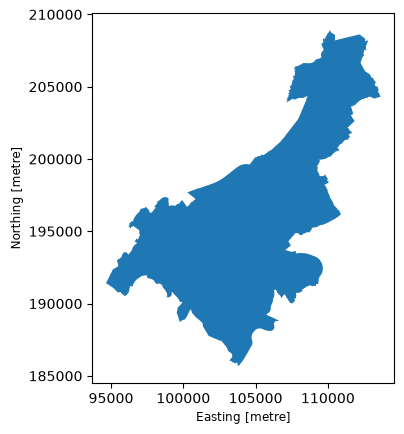

In [130]:
wfs_municipality = "https://geo.api.vlaanderen.be/VRBG2019/wfs"
params = dict(service='WFS', version='1.1.0', request='GetFeature',
              typeName='VRBG2019:Refgem', outputFormat='json',
              cql_filter="NAAM='Gent'", srs="31370")

# Fetch data from WFS using requests
r = requests.get(wfs_municipality, params=params)
gent = geopandas.GeoDataFrame.from_features(json.loads(r.content), crs="epsg:31370")
gent.plot()